### Comparação de classificadores na CTG

Este notebook escolhe os hiperparâmetros de quatro classificadores da statstech (regressão logística, LDA, QDA e KNN) por validaçaõ cruzada e compara-os. 


#### 0. Configuração inicial 

In [1]:
import csv
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
from statstech.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from statstech.linear_model import LogisticRegression
from statstech.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score
)
from statstech.neighbors import KNeighborsClassifier
from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import FIGURES, PROCESSED, SEED, STYLE, TABLES
from analysis.evaluation import evaluate_classifier
from analysis.io import load_dataset
from analysis.validation import StratifiedGroupKFold

plt.style.use(STYLE)

warnings.filterwarnings("ignore", message=".*indefinid.*")

CLASS_NAMES = ["normal", "suspeito", "patológico"]
PATHOLOGICAL = 2

#### 1. Dados e grupos do treino

ctg.npz traz treino e teste já separados por registro. Para a validação cruzada também precisamos saber de qual registro veio cada dado do treino.

In [2]:
data = load_dataset("ctg")
X_train, y_train = data["X_train"], data["y_train"]
feature_names = data["feature_names"].tolist()

groups_train = np.load(PROCESSED / "ctg_groups_train.npy")
assert len(groups_train) == len(y_train)

print(f"treino: {X_train.shape[0]} exames, {X_train.shape[1]} medidas, "
      f"{len(np.unique(groups_train))} registros")
for k, name in enumerate(CLASS_NAMES):
    n = np.sum(y_train == k)
    print(f"  {name:11s} {n:5d}  ({n / len(y_train):.1%})")

treino: 1755 exames, 20 medidas, 282 registros
  normal       1363  (77.7%)
  suspeito      245  (14.0%)
  patológico    147  (8.4%)


#### 2. Validação cruzada por registro

Segmentos do mesmo registro são muito parecidos. Se um cai no treino de um fold e outro na validação, o modelo "reconhece" o vizinho e a nota sobe sem o modelo ter aprendido nada que generalize. 


In [3]:
cv = StratifiedGroupKFold(groups_train, n_splits=10, random_state=SEED)

##### 2.1 KNN com folds por linha e por registro 

Busca por k com duas validações diferentes, mas com fold por linha segmentos "irmãos" se misturam entre treino e validação.

In [4]:
def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

ks = [1, 5, 15, 31, 61]
cv_by_row = StratifiedKFold(10, shuffle=True, random_state=SEED)
for label, splitter in [("folds por linha", cv_by_row), ("folds por registro", cv)]:
    search = GridSearchCV(make_pipeline(KNeighborsClassifier()), {"model__n_neighbors": ks},
                          cv=splitter, scoring="f1_macro").fit(X_train, y_train)
    print(f"{label:19s} melhor k = {search.best_params_['model__n_neighbors']:2d}   "
          f"F1 por k: {[round(r['mean_score'], 3) for r in search.cv_results_]}")

folds por linha     melhor k =  1   F1 por k: [0.834, 0.804, 0.786, 0.762, 0.722]
folds por registro  melhor k = 15   F1 por k: [0.694, 0.722, 0.723, 0.704, 0.663]


#### 3. Classificador baseline

Prever sempre a classe majoritária.

In [5]:
majority_class = np.bincount(y_train). argmax()
baseline = evaluate_classifier(y_train, np.full_like(y_train, majority_class))
print(f"acurácia {baseline['accuracy']:.3f} F1 macro {baseline['f1_macro']:.3f} "
      f"recall patológico {baseline['recall_2']:.3f}")

acurácia 0.777 F1 macro 0.291 recall patológico 0.000


#### 4. Busca de hiperparâmetros (F1 macro)

-> F1 macro: média do F1 das três classes.



In [6]:
grids = {
    "logistic": {"model__alpha": [0, 0.01, 0.1, 1, 10]},
    "lda": {"model__reg_param": [1e-6, 1e-3, 1e-1]},
    "qda": {"model__reg_param": [1e-4, 1e-2, 0.1, 0.3, 0.5]},
    "knn": {"model__n_neighbors": [1, 5, 15, 31, 61]},
}
searches = {}


def show_search(search):
    # Uma linha por valor da grade, com a média ± desvio entre folds.
    results = search.cv_results_
    for i, r in enumerate(results):
        value = next(iter(r["params"].values()))
        mark = "  <- melhor" if i == search.best_index_ else ""
        print(f"  {value!s:>8}   {r['mean_score']:.3f} ± {r['std_score']:.3f}{mark}")
    #Quando o melhor valor é o primeiro ou o último da grade
    if search.best_index_ in (0, len(results) - 1):
        print("o melhor valor está na borda da grade.")

##### 4.1 Regressão Logística 

In [7]:
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression()), grids["logistic"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["logistic"])

         0   0.786 ± 0.088  <- melhor
      0.01   0.786 ± 0.088
       0.1   0.786 ± 0.088
         1   0.781 ± 0.086
        10   0.776 ± 0.097
o melhor valor está na borda da grade.


Obs.: Como o melhor valor está na borda, talvez o modelo não tenha terminado de treinar. Vamos conferir inicialmente a convergência.

In [8]:
logistic = searches["logistic"].best_estimator_.named_steps_["model"]
loss = np.asarray(logistic.loss_history_)
print(f"iterações: {len(loss)} de max_iter = {logistic.max_iter}")
print(f"queda da perda nas últimas 100 iterações: {loss[-101] - loss[-1]:.4f}")

iterações: 1000 de max_iter = 1000
queda da perda nas últimas 100 iterações: 0.0022


A perda ainda estava caindo no final -> provavelmente não convergiu. 
Ideia: mais iterações ou passos maiores. 

In [9]:
alpha = searches["logistic"].best_params_["model__alpha"]
curves = {}
print("learning_rate  iterações  perda final  convergiu  perda sempre caindo")
for lr in [0.1, 0.5, 1.0, 2.0, 5.0]:
    model = make_pipeline(LogisticRegression(alpha=alpha, learning_rate=lr, max_iter=5000))
    history = np.asarray(model.fit(X_train, y_train).named_steps_["model"].loss_history_)
    curves[lr] = history
    print(f"{lr:13g}  {len(history):9d}  {history[-1]:11.4f}  {len(history) < 5000!s:>9}  "
          f"{bool(np.all(np.diff(history) <= 0))!s:>19}")

learning_rate  iterações  perda final  convergiu  perda sempre caindo
          0.1       5000       0.2118      False                 True
          0.5       2869       0.2064       True                 True
            1       1881       0.2057       True                 True
            2       1201       0.2054       True                 True
            5       5000       0.4058      False                False


Learning_rate = 1.0 é uma boa decisão entre os valores que convergem com a perda caindo. (Passos grandes são seguros pois as medidas estão padronizadas)

-> Nova busca, com o novo passo: 

In [10]:
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression(learning_rate=1.0, max_iter=5000)),
    grids["logistic"], cv=cv, scoring="f1_macro",
).fit(X_train, y_train)
show_search(searches["logistic"])

         0   0.774 ± 0.083
      0.01   0.774 ± 0.083
       0.1   0.769 ± 0.096
         1   0.772 ± 0.095
        10   0.780 ± 0.099  <- melhor
o melhor valor está na borda da grade.


Agora o melhor `alpha` é o 10 (último da grade). Vamos estender o grid para ver se o F1 macro continua aumentando:

In [11]:
grids["logistic"] = {"model__alpha": [0, 0.01, 0.1, 1, 10, 20, 100]}
searches["logistic"] = GridSearchCV(
    make_pipeline(LogisticRegression(learning_rate=1.0, max_iter=5000)),
    grids["logistic"], cv=cv, scoring="f1_macro",
).fit(X_train, y_train)
show_search(searches["logistic"])

         0   0.774 ± 0.083
      0.01   0.774 ± 0.083
       0.1   0.769 ± 0.096
         1   0.772 ± 0.095
        10   0.780 ± 0.099  <- melhor
        20   0.774 ± 0.092
       100   0.723 ± 0.074


##### 4.2 LDA

In [12]:
searches["lda"] = GridSearchCV(
    make_pipeline(LinearDiscriminantAnalysis()), grids["lda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["lda"])

     1e-06   0.715 ± 0.092  <- melhor
     0.001   0.712 ± 0.090
       0.1   0.708 ± 0.085
o melhor valor está na borda da grade.


Obs.: o valor está na borda, mas os três F1 macro são quase iguais e um valor abaixo de 1e-6 praticamente não regulariza nada.

##### 4.3 QDA

In [13]:
searches["qda"] = GridSearchCV(
    make_pipeline(QuadraticDiscriminantAnalysis()), grids["qda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["qda"])

    0.0001   0.670 ± 0.133
      0.01   0.689 ± 0.126
       0.1   0.694 ± 0.119
       0.3   0.713 ± 0.117
       0.5   0.733 ± 0.118  <- melhor
o melhor valor está na borda da grade.


Vamos estender a grade para observar se de fato 0.5 é o melhor: 

In [14]:
grids["qda"] = {"model__reg_param": [1e-4, 1e-2, 0.1, 0.3, 0.5, 0.7, 0.9]}
searches["qda"] = GridSearchCV(
    make_pipeline(QuadraticDiscriminantAnalysis()), grids["qda"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["qda"])

    0.0001   0.670 ± 0.133
      0.01   0.689 ± 0.126
       0.1   0.694 ± 0.119
       0.3   0.713 ± 0.117
       0.5   0.733 ± 0.118  <- melhor
       0.7   0.732 ± 0.109
       0.9   0.730 ± 0.109


De 0.5 a 0.9 o F1 macro fica estável, então `reg_param = 0.5` é suficiente.

##### 4.4 KNN

In [15]:
searches["knn"] = GridSearchCV(
    make_pipeline(KNeighborsClassifier()), grids["knn"], cv=cv, scoring="f1_macro"
).fit(X_train, y_train)
show_search(searches["knn"])

         1   0.694 ± 0.102
         5   0.722 ± 0.097
        15   0.723 ± 0.067  <- melhor
        31   0.704 ± 0.075
        61   0.663 ± 0.097


##### 4.5 F1 macro x hiperparâmetro

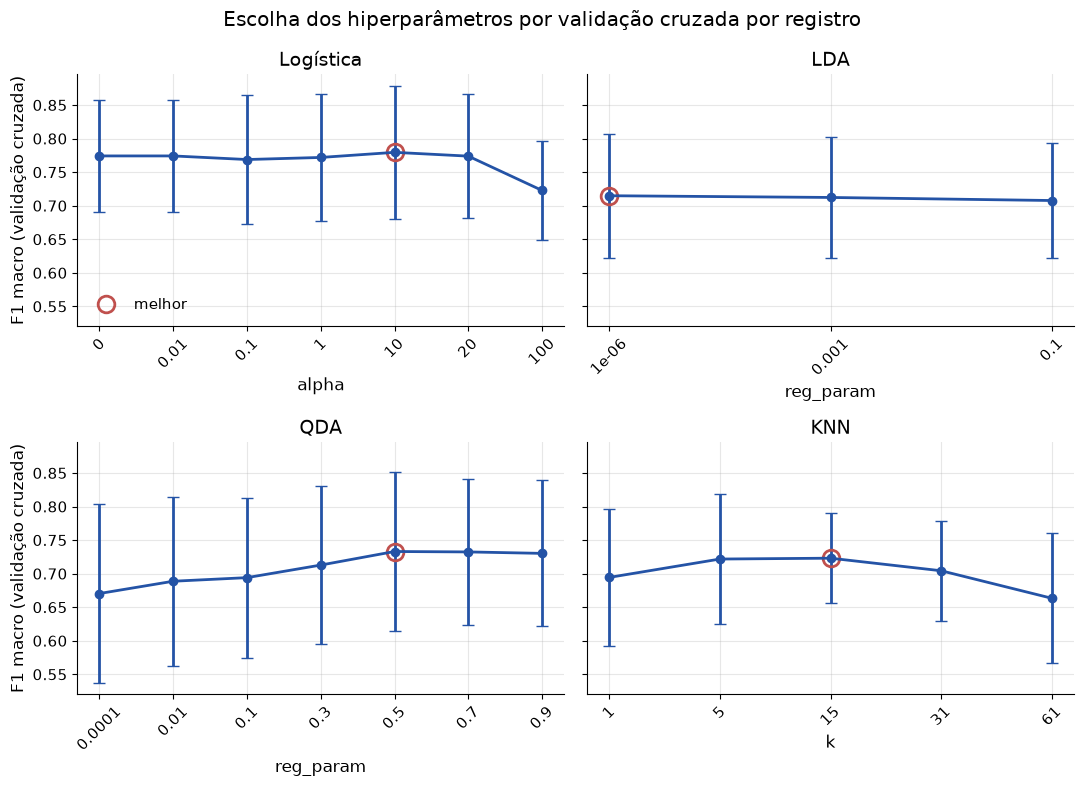

In [16]:
LABELS = {"logistic": "Logística", "lda": "LDA", "qda": "QDA", "knn": "KNN"}


def plot_search_curve(search, ax, title, xlabel):
    # TODO trocar pelo plot_search do C7
    results = search.cv_results_
    values = [next(iter(r["params"].values())) for r in results]
    mean = np.array([r["mean_score"] for r in results])
    std = np.array([r["std_score"] for r in results])
    x = np.arange(len(values))
    ax.errorbar(x, mean, yerr=std, marker="o", capsize=4)
    ax.plot(x[search.best_index_], mean[search.best_index_], "o", ms=12,
            mfc="none", mec="C1", mew=2, label="melhor")
    ax.set_xticks(x, [f"{v:g}" for v in values], rotation=45)
    ax.set_title(title)
    ax.set_xlabel(xlabel)


x_labels = {"logistic": "alpha", "lda": "reg_param", "qda": "reg_param", "knn": "k"}
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharey=True)
for ax, (key, search) in zip(axes.flat, searches.items()):
    plot_search_curve(search, ax, LABELS[key], x_labels[key])
for ax in axes[:, 0]:
    ax.set_ylabel("F1 macro (validação cruzada)")
axes[0, 0].legend()
fig.suptitle("Escolha dos hiperparâmetros por validação cruzada por registro")
fig.tight_layout()
fig.savefig(FIGURES / "ctg_busca.png")
plt.show()

#### 5. Recall do patológico

In [17]:
def pathological_recall(y_true, y_pred):
    return evaluate_classifier(y_true, y_pred)[f"recall_{PATHOLOGICAL}"]


recall = {}
for key, search in searches.items():
    scores = cross_val_score(search.best_estimator_, X_train, y_train, cv=cv,
                             scoring=pathological_recall)
    recall[key] = {"mean": scores.mean(), "std": scores.std(ddof=1)}
    print(f"{LABELS[key]:10s} recall patológico {scores.mean():.3f} ± {scores.std(ddof=1):.3f}")

Logística  recall patológico 0.718 ± 0.284
LDA        recall patológico 0.578 ± 0.321
QDA        recall patológico 0.543 ± 0.308
KNN        recall patológico 0.579 ± 0.258


Obs.: Errar para "suspeito" é bem menos grave que errar para o "normal". 

In [18]:
n_pathological = np.sum(y_train == PATHOLOGICAL)
for key, search in searches.items():
    y_pred = cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv)
    as_normal = np.sum((y_train == PATHOLOGICAL) & (y_pred == 0))
    as_suspect = np.sum((y_train == PATHOLOGICAL) & (y_pred == 1))
    print(f"{LABELS[key]:10s} dos {n_pathological} patológicos: {as_normal:2d} viraram normal, "
          f"{as_suspect:2d} viraram suspeito")

Logística  dos 147 patológicos: 16 viraram normal, 23 viraram suspeito
LDA        dos 147 patológicos: 14 viraram normal, 44 viraram suspeito
QDA        dos 147 patológicos: 12 viraram normal, 51 viraram suspeito
KNN        dos 147 patológicos: 32 viraram normal, 28 viraram suspeito


#### 6. Variante com as medidas assimétricas transformadas

In [19]:
def skewness(X):
    # Assimetria de cada coluna: média do cubo dos desvios / desvio ao cubo.
    centered = X - X.mean(axis=0)
    return (centered**3).mean(axis=0) / X.std(axis=0) ** 3


skew = skewness(X_train)
skewed_cols = [name for name, s, low in zip(feature_names, skew, X_train.min(axis=0))
               if s > 1 and low >= 0]
skewed_idx = [feature_names.index(name) for name in skewed_cols]
skew_log = skewness(np.log1p(X_train[:, skewed_idx]))

print("medida     maior valor  assimetria  depois do log1p")
for name, j, s_log in zip(skewed_cols, skewed_idx, skew_log):
    print(f"{name:9s} {X_train[:, j].max():12.4g}  {skew[j]:10.2f}  {s_log:15.2f}")

medida     maior valor  assimetria  depois do log1p
AC             0.01928        1.18             1.18
FM              0.4299        8.86             8.42
MSTV               6.9        1.65             0.46
ALTV                91        2.27             0.85
MLTV              50.7        1.45            -1.10
DL             0.01538        1.64             1.63
DS            0.001079       29.97            29.97
DP            0.005348        4.07             4.07
Nzeros              10        3.58             1.70
Variance           215        2.67             0.13


O log1p não altera AC, FM, DL, DS e DP. Como essas medidas são muito pequenas (taxas por segundo), `log1p(x) ≈ x`, a transformação não altera praticmaente nada. 
Ideia: passar as taxas para hora (x 3600) antes do log1p

In [20]:
RATES = ["AC", "FM", "UC", "DL", "DS", "DP"]  # eventos por segundo


def transform_skewed(X):
    # log1p nas medidas assimétricas; taxas por segundo viram por hora antes.
    X = X.copy()
    for name in skewed_cols:
        j = feature_names.index(name)
        scale = 3600 if name in RATES else 1
        X[:, j] = np.log1p(X[:, j] * scale)
    return X


X_train_log = transform_skewed(X_train)
skew_new = skewness(X_train_log)
print("medida     assimetria  depois (com taxas por hora)")
for name, j in zip(skewed_cols, skewed_idx):
    print(f"{name:9s} {skew[j]:10.2f}  {skew_new[j]:27.2f}")

medida     assimetria  depois (com taxas por hora)
AC              1.18                         0.05
FM              8.86                         1.38
MSTV            1.65                         0.46
ALTV            2.27                         0.85
MLTV            1.45                        -1.10
DL              1.64                         0.56
DS             29.97                        29.68
DP              4.07                         3.09
Nzeros          3.58                         1.70
Variance        2.67                         0.13


A assimetria diminui em quase todas as medidas, com exceção de DS que é zero em quase todo o treino. 

Agora vamos repetir LDA e QDA com as medidas transformadas, com as mesmas grades:

In [21]:
searches_log, recall_log = {}, {}
for key, model in [("lda", LinearDiscriminantAnalysis()),
                   ("qda", QuadraticDiscriminantAnalysis())]:
    searches_log[key] = GridSearchCV(make_pipeline(model), grids[key], cv=cv,
                                     scoring="f1_macro").fit(X_train_log, y_train)
    print(LABELS[key], "com log1p")
    show_search(searches_log[key])
    scores = cross_val_score(searches_log[key].best_estimator_, X_train_log, y_train,
                             cv=cv, scoring=pathological_recall)
    recall_log[key] = {"mean": scores.mean(), "std": scores.std(ddof=1)}

LDA com log1p
     1e-06   0.722 ± 0.114  <- melhor
     0.001   0.722 ± 0.114
       0.1   0.719 ± 0.114
o melhor valor está na borda da grade.
QDA com log1p
    0.0001   0.692 ± 0.121
      0.01   0.695 ± 0.124
       0.1   0.706 ± 0.118
       0.3   0.722 ± 0.124
       0.5   0.729 ± 0.125
       0.7   0.732 ± 0.121  <- melhor
       0.9   0.731 ± 0.121


#### 7. Tabela Comparativa 

Uma linha por modelo, com o hiperparâmetro escolhido, o F1 macro e o recall do patológico (média ± desvio entre os 10 folds) 

In [22]:
def table_row(label, search, rec):
    best = search.cv_results_[search.best_index_]
    (param, value), = best["params"].items()
    return {
        "model": label,
        "hyperparameter": f"{param.removeprefix('model__')}={value:g}",
        "f1_macro": best["mean_score"],
        "f1_macro_std": best["std_score"],
        "pathological_recall": rec["mean"],
        "pathological_recall_std": rec["std"],
    }


BASELINE_LABEL = "Referência (majoritária)"
table = [{"model": BASELINE_LABEL, "hyperparameter": "-",
          "f1_macro": baseline["f1_macro"], "f1_macro_std": 0.0,
          "pathological_recall": baseline["recall_2"], "pathological_recall_std": 0.0}]
table += [table_row(LABELS[k], s, recall[k]) for k, s in searches.items()]
table += [table_row(f"{LABELS[k]} (log)", s, recall_log[k]) for k, s in searches_log.items()]

print(f"{'modelo':26s} {'hiperparâmetro':18s} {'F1 macro':>15s} {'recall patológico':>18s}")
for row in table:
    print(f"{row['model']:26s} {row['hyperparameter']:18s} "
          f"{row['f1_macro']:.3f} ± {row['f1_macro_std']:.3f}  "
          f"{row['pathological_recall']:.3f} ± {row['pathological_recall_std']:.3f}")

# TODO trocar por save_table do C7
with open(TABLES / "ctg_comparacao.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(table[0]))
    writer.writeheader()
    for row in table:
        writer.writerow({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})

modelo                     hiperparâmetro            F1 macro  recall patológico
Referência (majoritária)   -                  0.291 ± 0.000  0.000 ± 0.000
Logística                  alpha=10           0.780 ± 0.099  0.718 ± 0.284
LDA                        reg_param=1e-06    0.715 ± 0.092  0.578 ± 0.321
QDA                        reg_param=0.5      0.733 ± 0.118  0.543 ± 0.308
KNN                        n_neighbors=15     0.723 ± 0.067  0.579 ± 0.258
LDA (log)                  reg_param=1e-06    0.722 ± 0.114  0.556 ± 0.327
QDA (log)                  reg_param=0.7      0.732 ± 0.121  0.555 ± 0.326


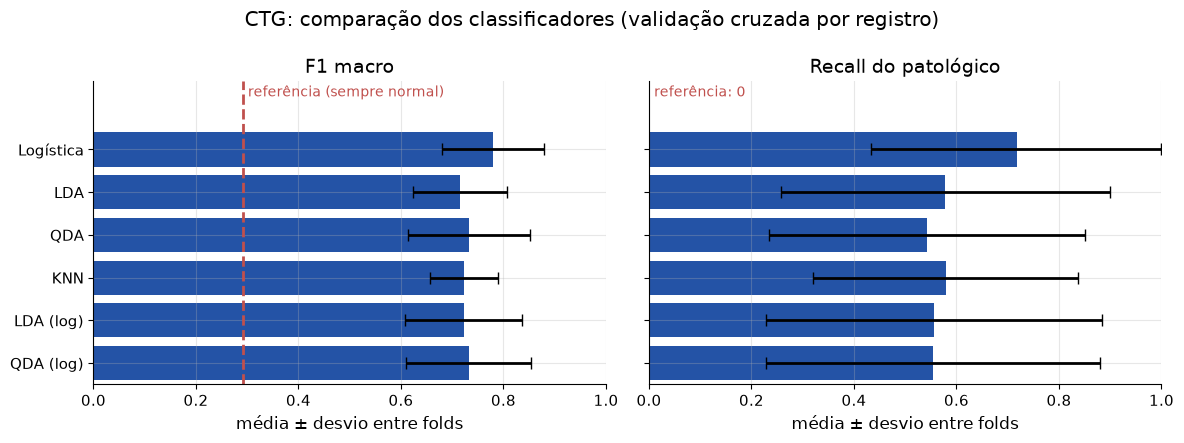

In [23]:
plotted = [row for row in table if row["model"] != BASELINE_LABEL]
y_pos = np.arange(len(plotted))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, metric, title in [(axes[0], "f1_macro", "F1 macro"),
                          (axes[1], "pathological_recall", "Recall do patológico")]:
    mean = np.array([row[metric] for row in plotted])
    std = np.array([row[f"{metric}_std"] for row in plotted])
    # Barras de erro cortadas em [0, 1]: a métrica não sai desse intervalo.
    err = [mean - np.clip(mean - std, 0, 1), np.clip(mean + std, 0, 1) - mean]
    ax.barh(y_pos, mean, xerr=err, capsize=4, color="C0")
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("média ± desvio entre folds")
axes[0].axvline(baseline["f1_macro"], color="C1", ls="--")
axes[0].set_yticks(y_pos, [row["model"] for row in plotted])
axes[0].set_ylim(len(plotted) - 0.5, -1.6)  # de cima para baixo, com espaço para o rótulo
axes[0].text(baseline["f1_macro"] + 0.01, -1.5, "referência (sempre normal)", color="C1",
             va="top", fontsize=10)
axes[1].text(0.01, -1.5, "referência: 0", color="C1", va="top", fontsize=10)
fig.suptitle("CTG: comparação dos classificadores (validação cruzada por registro)")
fig.tight_layout()
fig.savefig(FIGURES / "ctg_comparacao.png")
plt.show()

#### 8. Hiperparâmetros escolhidos

(salvos para as próximas etapas)

In [24]:
FIXED = {"logistic": {"model__learning_rate": 1.0, "model__max_iter": 5000}}

best = {}
for key, search in searches.items():
    uses_log = key in searches_log and (
        searches_log[key].best_score_ > search.best_score_ + 0.01)
    chosen = searches_log[key] if uses_log else search
    best[key] = {
        "fixed": FIXED.get(key, {}),
        "params": chosen.best_params_,
        "f1_macro_cv": float(chosen.best_score_),
        "uses_log1p": bool(uses_log),
    }
    print(f"{LABELS[key]:10s} {best[key]['params']}  F1 {chosen.best_score_:.3f}"
          f"{'  (com log1p)' if uses_log else ''}")

with open(TABLES / "ctg_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, **best}, f, indent=2)

Logística  {'model__alpha': 10}  F1 0.780
LDA        {'model__reg_param': 1e-06}  F1 0.715
QDA        {'model__reg_param': 0.5}  F1 0.733
KNN        {'model__n_neighbors': 15}  F1 0.723


#### 9. Conclusão da comparação de classificadores na CTG

- A validação por registro muda a escolha. 

- Melhor modelo por F1 macro: logística com `alpha = 10` (0,780 ± 0,099).

- Recall do patológico: a logística tem o maior (0,718), mas o desvio entre folds é enorme (± 0,28). O KNN é o que mais manda patológicos para "normal".

- Baseline: a classe majoritária acerta 77,7% dos exames, mas tem F1 macro 0,291 e recall patológico zero. Todos os modelos ganham dela, e é por isso que não reportamos só a acurácia.